# Exploratory Data Analysis: Environmental Pollution Monitoring

This notebook explores air-quality and emissions patterns in `global_climate_impact_1990_2025.csv` using country-year observations.

### Questions explored
- How complete are the main pollution measurements, and how does coverage change over time?
- What are the long-term patterns in particulate matter and reported CO₂ emissions?
- Which countries and continents have higher recent particulate readings?
- How are pollution indicators associated with respiratory disease rates in this dataset?

**Interpret with care:** country observations are equally weighted, not population-weighted, and do not show within-country exposure. WHO 2021 annual guideline values (PM2.5: 5 µg/m³; PM10: 15 µg/m³) are shown as health-based reference values, not as a regulatory determination. Correlation is descriptive and does not establish causation. Verify source, definitions, and measurement methods before using the results for decisions.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

CSV_NAME = "global_climate_impact_1990_2025.csv"
data_path = next(
    (parent / CSV_NAME for parent in (Path.cwd(), *Path.cwd().parents)
     if (parent / CSV_NAME).is_file()),
    None,
)
if data_path is None:
    raise FileNotFoundError(
        f"Could not find {CSV_NAME!r} in the current directory or its parents."
    )

df = pd.read_csv(data_path)
required_columns = {
    "Country", "Continent", "Year", "PM2_5_Annual_Mean_ug_m3",
    "PM10_Annual_Mean_ug_m3", "CO2_Emissions_Total_Mt",
    "Respiratory_Disease_Rate_Per100k",
}
missing_columns = required_columns.difference(df.columns)
if missing_columns:
    raise ValueError(f"CSV is missing required columns: {sorted(missing_columns)}")

df["Year"] = pd.to_numeric(df["Year"], errors="raise").astype(int)
print(f"Loaded {len(df):,} records across {df['Country'].nunique():,} countries")
print(f"Year coverage: {df['Year'].min()}–{df['Year'].max()}")
print(f"Duplicate country-year records: {df.duplicated(['Country', 'Year']).sum():,}")

Loaded 6,948 records across 193 countries
Year coverage: 1990–2025
Duplicate country-year records: 0


## 1. Data quality and pollutant distributions

Missing values are kept as missing during this exploratory analysis; each metric uses its available observations.

In [2]:
pollution_columns = [
    "PM2_5_Annual_Mean_ug_m3", "PM10_Annual_Mean_ug_m3",
    "Air_Quality_Index", "Ozone_Annual_Mean_ug_m3",
    "NO2_Annual_Mean_ug_m3", "CO2_Emissions_Total_Mt",
    "Respiratory_Disease_Rate_Per100k",
]
available_columns = [column for column in pollution_columns if column in df.columns]
quality = pd.DataFrame({
    "observed_n": df[available_columns].count(),
    "missing_n": df[available_columns].isna().sum(),
    "missing_pct": (df[available_columns].isna().mean() * 100).round(2),
})
display(quality)
display(df[available_columns].describe().T.round(2))

,observed_n,missing_n,missing_pct
PM2_5_Annual_Mean_ug_m3,6452,496,7.14
PM10_Annual_Mean_ug_m3,6447,501,7.21
Air_Quality_Index,6479,469,6.75
Ozone_Annual_Mean_ug_m3,6917,31,0.45
NO2_Annual_Mean_ug_m3,6916,32,0.46
CO2_Emissions_Total_Mt,6922,26,0.37
Respiratory_Disease_Rate_Per100k,6925,23,0.33


,count,mean,std,min,25%,50%,75%,max
PM2_5_Annual_Mean_ug_m3,6452.0,24.40,12.78,2.0,14.25,22.37,32.94,64.03
PM10_Annual_Mean_ug_m3,6447.0,37.77,20.09,4.0,21.76,34.52,51.03,104.21
Air_Quality_Index,6479.0,56.02,29.78,5.0,32.85,51.30,75.50,156.70
Ozone_Annual_Mean_ug_m3,6917.0,32.83,10.03,5.0,25.56,32.42,39.62,67.70
NO2_Annual_Mean_ug_m3,6916.0,20.92,9.11,2.0,13.98,20.22,27.16,53.45
CO2_Emissions_Total_Mt,6922.0,0.58,2.05,0.0,0.02,0.07,0.29,28.20
Respiratory_Disease_Rate_Per100k,6925.0,411.70,127.28,85.1,314.30,395.30,495.90,830.50


## 2. Long-term particulate pollution and data coverage

The annual mean is calculated across countries with reported measurements. It is not a population-weighted global exposure estimate. The lower panel makes changes in the number of reporting countries visible.

In [3]:
PM25_GUIDELINE = 5.0
PM10_GUIDELINE = 15.0
annual = df.groupby("Year").agg(
    PM2_5_mean=("PM2_5_Annual_Mean_ug_m3", "mean"),
    PM2_5_countries=("PM2_5_Annual_Mean_ug_m3", "count"),
    PM10_mean=("PM10_Annual_Mean_ug_m3", "mean"),
    PM10_countries=("PM10_Annual_Mean_ug_m3", "count"),
)

fig, axes = plt.subplots(2, 1, figsize=(12, 9), sharex=True)
axes[0].plot(annual.index, annual["PM2_5_mean"], color="#b23a48", label="PM2.5")
axes[0].axhline(PM25_GUIDELINE, color="black", linestyle="--",
                label="WHO annual guideline: 5 µg/m³")
axes[0].set_ylabel("PM2.5 (µg/m³)")
axes[0].set_title("Country-average annual particulate matter")
axes[0].legend(frameon=False)
axes[0].grid(alpha=0.25)
axes[1].plot(annual.index, annual["PM10_mean"], color="#28666e", label="PM10")
axes[1].axhline(PM10_GUIDELINE, color="black", linestyle="--",
                label="WHO annual guideline: 15 µg/m³")
axes[1].set_ylabel("PM10 (µg/m³)")
axes[1].set_xlabel("Year")
axes[1].legend(frameon=False)
axes[1].grid(alpha=0.25)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(annual.index, annual["PM2_5_countries"], label="PM2.5 reporting countries")
ax.plot(annual.index, annual["PM10_countries"], label="PM10 reporting countries")
ax.set(title="Annual particulate data coverage", xlabel="Year", ylabel="Countries")
ax.legend(frameon=False)
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()
display(annual.loc[[annual.index.min(), annual.index.max()]].round(2))

<Figure size 1200x900 with 2 Axes>

<Figure size 1200x400 with 1 Axes>

,PM2_5_mean,PM2_5_countries,PM10_mean,PM10_countries
Year,,,,
1990,24.70,124,39.34,113
2025,19.82,192,30.62,191


## 3. Latest-year country and continent patterns

Exceedance percentages use only countries with a non-missing observation for that measure. These rankings are screening summaries, not measures of population exposure.

PM2_5_Annual_Mean_ug_m3: 182/192 countries (94.8%) above 5 µg/m³ in 2025; mean=19.82, median=17.18 µg/m³
PM10_Annual_Mean_ug_m3: 152/191 countries (79.6%) above 15 µg/m³ in 2025; mean=30.62, median=26.58 µg/m³


,PM2_5_mean,PM2_5_countries,PM10_mean,PM10_countries
Continent,,,,
Asia,22.64,47,34.55,48
North America,21.20,23,33.14,23
Europe,21.13,43,32.96,43
Oceania,19.90,14,30.13,14
South America,19.19,12,30.27,12
Africa,15.78,53,24.02,51


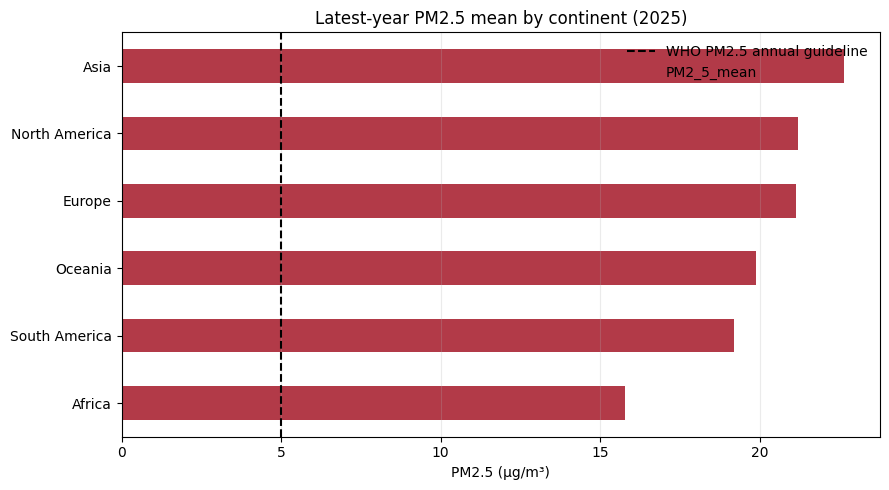

,Country,Continent,PM2_5_Annual_Mean_ug_m3,PM10_Annual_Mean_ug_m3
0,Turkmenistan,Asia,60.15,93.58
1,Angola,Africa,54.65,82.54
2,Brunei,Asia,52.86,72.35
3,Iraq,Asia,52.25,75.51
4,Hungary,Europe,50.66,82.36
5,Algeria,Africa,50.32,75.51
6,Antigua and Barbuda,North America,48.40,72.97
7,Belarus,Europe,48.27,75.73
8,Australia,Oceania,47.60,67.29
9,Kuwait,Asia,47.46,79.70


In [4]:
latest_year = int(df["Year"].max())
latest = df.loc[df["Year"].eq(latest_year)].copy()
for column, guideline in [
    ("PM2_5_Annual_Mean_ug_m3", PM25_GUIDELINE),
    ("PM10_Annual_Mean_ug_m3", PM10_GUIDELINE),
]:
    observed = latest[column].dropna()
    if observed.empty:
        print(f"{column}: no observations in {latest_year}")
        continue
    above = int(observed.gt(guideline).sum())
    print(
        f"{column}: {above}/{len(observed)} countries "
        f"({observed.gt(guideline).mean() * 100:.1f}%) above {guideline:g} µg/m³ "
        f"in {latest_year}; mean={observed.mean():.2f}, "
        f"median={observed.median():.2f} µg/m³"
    )

regional = latest.groupby("Continent").agg(
    PM2_5_mean=("PM2_5_Annual_Mean_ug_m3", "mean"),
    PM2_5_countries=("PM2_5_Annual_Mean_ug_m3", "count"),
    PM10_mean=("PM10_Annual_Mean_ug_m3", "mean"),
    PM10_countries=("PM10_Annual_Mean_ug_m3", "count"),
).sort_values("PM2_5_mean", ascending=False)
display(regional.round(2))

fig, ax = plt.subplots(figsize=(9, 5))
regional["PM2_5_mean"].sort_values().plot.barh(ax=ax, color="#b23a48")
ax.axvline(PM25_GUIDELINE, color="black", linestyle="--",
           label="WHO PM2.5 annual guideline")
ax.set(title=f"Latest-year PM2.5 mean by continent ({latest_year})",
       xlabel="PM2.5 (µg/m³)", ylabel="")
ax.legend(frameon=False)
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

top_pm25 = latest.nlargest(10, "PM2_5_Annual_Mean_ug_m3")[
    ["Country", "Continent", "PM2_5_Annual_Mean_ug_m3", "PM10_Annual_Mean_ug_m3"]
]
display(top_pm25.reset_index(drop=True).round(2))

## 4. Reported CO₂ emissions

CO₂ emissions are a total emissions measure, not an ambient air concentration. The yearly sum includes countries with available values, so reporting counts are shown alongside it.

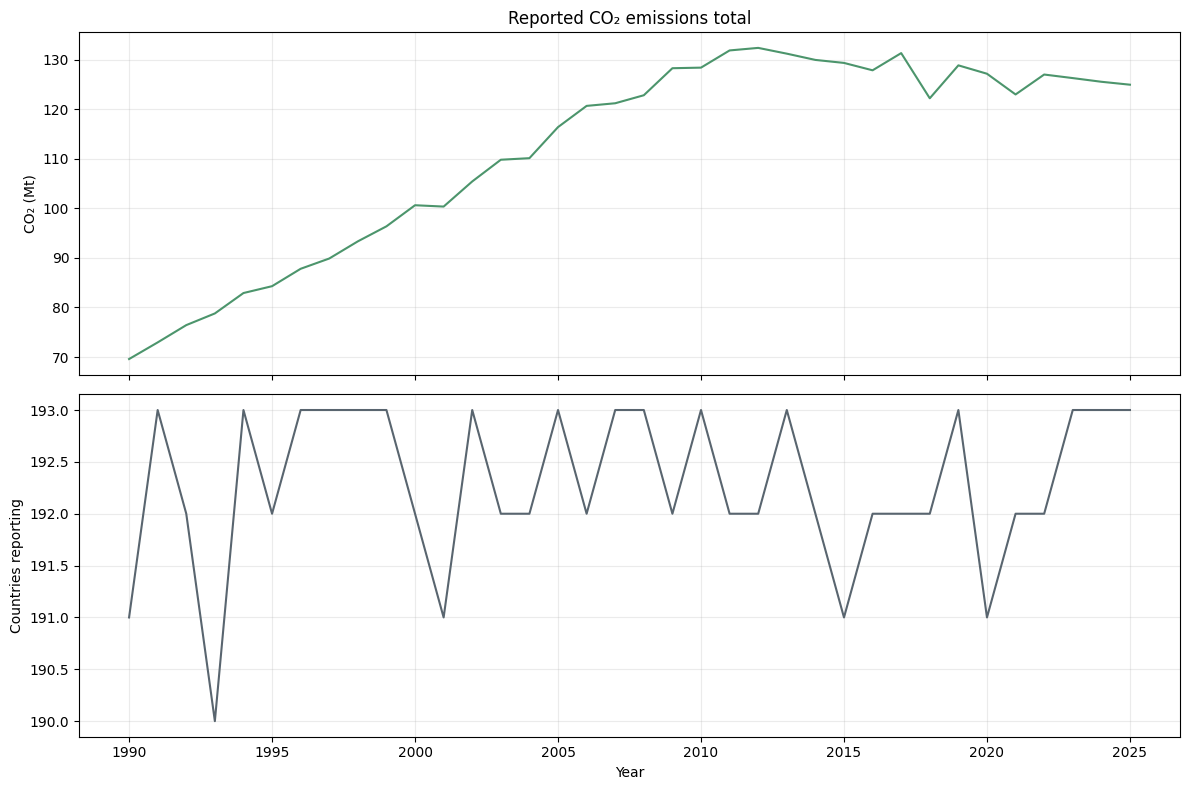

,reported_CO2_Mt,reporting_countries
Year,,
1990,69.595,191
2025,124.970,193


In [5]:
co2_annual = df.groupby("Year").agg(
    reported_CO2_Mt=("CO2_Emissions_Total_Mt", "sum"),
    reporting_countries=("CO2_Emissions_Total_Mt", "count"),
)
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
axes[0].plot(co2_annual.index, co2_annual["reported_CO2_Mt"], color="#4c956c")
axes[0].set_ylabel("CO₂ (Mt)")
axes[0].set_title("Reported CO₂ emissions total")
axes[0].grid(alpha=0.25)
axes[1].plot(co2_annual.index, co2_annual["reporting_countries"], color="#59656f")
axes[1].set(xlabel="Year", ylabel="Countries reporting")
axes[1].grid(alpha=0.25)
plt.tight_layout()
plt.show()
display(co2_annual.loc[[co2_annual.index.min(), co2_annual.index.max()]])

## 5. Pollution and respiratory disease association

The correlation matrix and scatter plot are exploratory. Country-year observations repeat countries over time and may be affected by confounders; results do not establish individual risk or causation.

,PM2_5_Annual_Mean_ug_m3,PM10_Annual_Mean_ug_m3,Air_Quality_Index,Ozone_Annual_Mean_ug_m3,NO2_Annual_Mean_ug_m3,Respiratory_Disease_Rate_Per100k
PM2_5_Annual_Mean_ug_m3,1.00,0.99,0.99,0.67,0.85,0.95
PM10_Annual_Mean_ug_m3,0.99,1.00,0.98,0.67,0.85,0.94
Air_Quality_Index,0.99,0.98,1.00,0.66,0.84,0.94
Ozone_Annual_Mean_ug_m3,0.67,0.67,0.66,1.00,0.67,0.64
NO2_Annual_Mean_ug_m3,0.85,0.85,0.84,0.67,1.00,0.81
Respiratory_Disease_Rate_Per100k,0.95,0.94,0.94,0.64,0.81,1.00


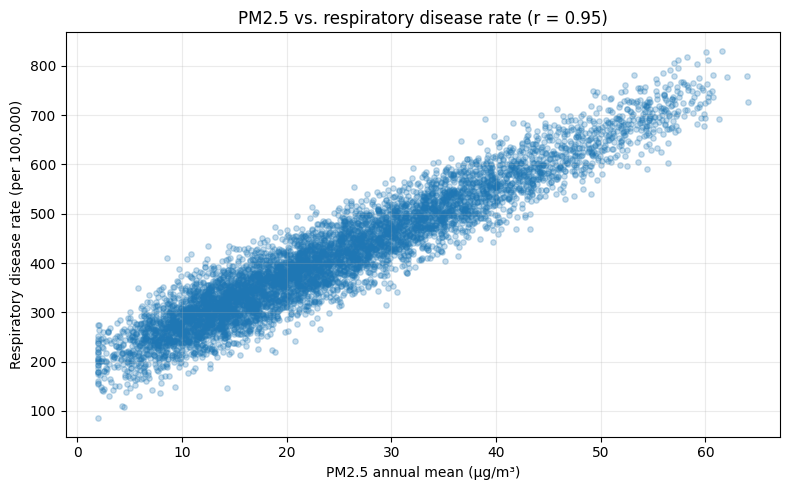

In [6]:
health_columns = [
    "PM2_5_Annual_Mean_ug_m3", "PM10_Annual_Mean_ug_m3",
    "Air_Quality_Index", "Ozone_Annual_Mean_ug_m3",
    "NO2_Annual_Mean_ug_m3", "Respiratory_Disease_Rate_Per100k",
]
health_columns = [column for column in health_columns if column in df.columns]
correlations = df[health_columns].corr(method="pearson", min_periods=30)
display(correlations.round(2))

x_column = "PM2_5_Annual_Mean_ug_m3"
y_column = "Respiratory_Disease_Rate_Per100k"
paired = df[[x_column, y_column]].dropna()
if len(paired) >= 2:
    r = paired[x_column].corr(paired[y_column])
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.scatter(paired[x_column], paired[y_column], alpha=0.25, s=15)
    ax.set(title=f"PM2.5 vs. respiratory disease rate (r = {r:.2f})",
           xlabel="PM2.5 annual mean (µg/m³)",
           ylabel="Respiratory disease rate (per 100,000)")
    ax.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()
else:
    print("Not enough paired measurements to plot this relationship.")

## Key limitations and next steps

- Annual country averages conceal variation within countries; use city or monitoring-station data for local pollution surveillance.
- Country-level averages are not population-weighted, so they do not estimate the fraction of people exposed.
- Missing observations are excluded metric by metric. Changing reporting coverage can affect trends and comparisons.
- Compare CO₂ totals separately from ambient concentrations; these measures are not interchangeable.
- Correlations are descriptive only. Assessing health impacts requires validated data, confounder adjustment, and an appropriate study design.

**Recommended next step:** verify dataset provenance, units, and indicator definitions, then add validated station-level measurements and population weights for operational monitoring.